In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("deeplumiere/hyperscale-data-center-dataset")

print("Path to dataset files:", path)

100%|██████████| 7.46M/7.46M [00:00<00:00, 189MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/deeplumiere/hyperscale-data-center-dataset/versions/1


In [5]:
import os
print(os.listdir(path))

['dataset_summary.txt', 'correlation_matrix.csv', 'green_ai_datacenter.csv', 'dataset_metadata.json']


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.model_selection import train_test_split, RandomizedSearchCV, PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import SMOTE

In [7]:
df = pd.read_csv(os.path.join(path,"green_ai_datacenter.csv"))

In [8]:
df.head()

,server_type,cooling_type,datacenter_region,time_of_day,maintenance_status,energy_source_primary,server_age_years,rack_u_position,workload_intensity,cpu_utilization,...,ups_battery_health,power_consumption_kw,pue,wue,carbon_intensity_gco2_kwh,renewable_energy_ratio,carbon_emission_kg,compute_cost_usd,energy_efficiency_class,failure_risk_level
0,Edge,Air,EU,Night,Normal,Solar,8,38,0.615,46.498,...,63.263,61.939,1.137,0.268,177.167,0.893,1.340,14.090,High,Medium
1,GPU,Liquid,EU,Off-Peak,Normal,Solar,2,17,0.295,21.285,...,88.992,206.840,1.050,2.353,198.353,0.723,11.935,43.436,High,Low
2,Compute,Hybrid,ME,Peak,Normal,Grid,3,1,0.683,52.201,...,78.130,96.127,1.050,0.220,444.571,0.015,44.217,10.093,Low,Low
3,Compute,Air,NaN,Off-Peak,Normal,Grid,7,39,0.416,32.406,...,66.360,100.631,1.123,0.391,328.678,0.329,24.919,16.954,Low,Medium
4,GPU,Liquid,EU,Night,Normal,Hydro,2,24,0.278,27.067,...,94.749,218.814,1.050,1.779,190.772,0.767,10.219,45.951,High,Low


In [9]:
df.describe()

,server_age_years,rack_u_position,workload_intensity,cpu_utilization,gpu_utilization,memory_utilization,storage_utilization,disk_io_iops,network_throughput_gbps,network_latency_ms,...,cooling_efficiency,power_supply_efficiency,ups_battery_health,power_consumption_kw,pue,wue,carbon_intensity_gco2_kwh,renewable_energy_ratio,carbon_emission_kg,compute_cost_usd
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,5.21625,21.513920,0.551330,47.170051,12.767987,56.545369,34.465213,6203.171996,15.505967,59.627713,...,0.945376,0.927837,79.050331,137.815112,1.099742,0.811080,353.354615,0.514874,28.282059,23.345205
std,3.01260,12.117263,0.259524,18.771294,23.307380,12.669366,22.080381,2559.101510,7.531797,33.432017,...,0.055436,0.030126,12.871266,90.226820,0.061745,0.766077,142.922863,0.270469,29.770134,18.013494
min,1.00000,1.000000,0.100000,7.237000,0.000000,5.000000,10.001000,1513.636000,1.267000,5.001000,...,0.835000,0.870000,40.000000,20.135000,1.050000,0.100000,118.381000,0.000000,0.000000,2.307000
25%,2.00000,11.000000,0.328000,31.495000,0.000000,47.803000,19.124750,4374.717500,10.226000,37.948000,...,0.895000,0.900000,68.676000,74.364000,1.050000,0.249000,207.896000,0.266000,7.228000,11.400000
50%,5.00000,22.000000,0.551000,47.180500,0.000000,56.570000,28.276000,5746.019500,14.139500,59.203000,...,0.960000,0.930000,79.610500,103.907000,1.061000,0.398000,345.729000,0.520000,16.265000,15.122000
75%,8.00000,32.000000,0.776000,62.937000,19.430250,65.312000,37.486000,7445.928000,19.343000,80.069000,...,1.000000,0.960000,90.012000,206.464500,1.151000,1.513000,521.486500,0.762000,45.755500,31.043500
max,11.00000,42.000000,1.000000,93.719000,100.000000,98.000000,95.000000,14461.720000,75.131000,299.987000,...,1.000000,0.970000,100.000000,935.354000,1.263000,2.500000,641.587000,1.000000,253.585000,94.717000


In [10]:
df.shape

(100000, 35)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   server_type                100000 non-null  object 
 1   cooling_type               100000 non-null  object 
 2   datacenter_region          71199 non-null   object 
 3   time_of_day                100000 non-null  object 
 4   maintenance_status         100000 non-null  object 
 5   energy_source_primary      100000 non-null  object 
 6   server_age_years           100000 non-null  int64  
 7   rack_u_position            100000 non-null  int64  
 8   workload_intensity         100000 non-null  float64
 9   cpu_utilization            100000 non-null  float64
 10  gpu_utilization            100000 non-null  float64
 11  memory_utilization         100000 non-null  float64
 12  storage_utilization        100000 non-null  float64
 13  disk_io_iops               100

In [12]:
print(df.isnull().sum())

server_type                      0
cooling_type                     0
datacenter_region            28801
time_of_day                      0
maintenance_status               0
energy_source_primary            0
server_age_years                 0
rack_u_position                  0
workload_intensity               0
cpu_utilization                  0
gpu_utilization                  0
memory_utilization               0
storage_utilization              0
disk_io_iops                     0
network_throughput_gbps          0
network_latency_ms               0
virtual_machines_count           0
ambient_temperature_c            0
humidity_percentage              0
inlet_temperature_c              0
exhaust_temperature_c            0
fan_speed_rpm                    0
airflow_cfm                      0
cooling_efficiency               0
power_supply_efficiency          0
ups_battery_health               0
power_consumption_kw             0
pue                              0
wue                 

In [13]:
df['datacenter_region'] = df['datacenter_region'].fillna(df['datacenter_region'].mode()[0])

In [14]:
print(df.isnull().sum())

server_type                  0
cooling_type                 0
datacenter_region            0
time_of_day                  0
maintenance_status           0
energy_source_primary        0
server_age_years             0
rack_u_position              0
workload_intensity           0
cpu_utilization              0
gpu_utilization              0
memory_utilization           0
storage_utilization          0
disk_io_iops                 0
network_throughput_gbps      0
network_latency_ms           0
virtual_machines_count       0
ambient_temperature_c        0
humidity_percentage          0
inlet_temperature_c          0
exhaust_temperature_c        0
fan_speed_rpm                0
airflow_cfm                  0
cooling_efficiency           0
power_supply_efficiency      0
ups_battery_health           0
power_consumption_kw         0
pue                          0
wue                          0
carbon_intensity_gco2_kwh    0
renewable_energy_ratio       0
carbon_emission_kg           0
compute_

In [15]:
print(df.duplicated().sum())

0


In [16]:
df['failure_risk_level'].value_counts(normalize=True)

,proportion
failure_risk_level,
Low,0.49253
Medium,0.34479
High,0.16268


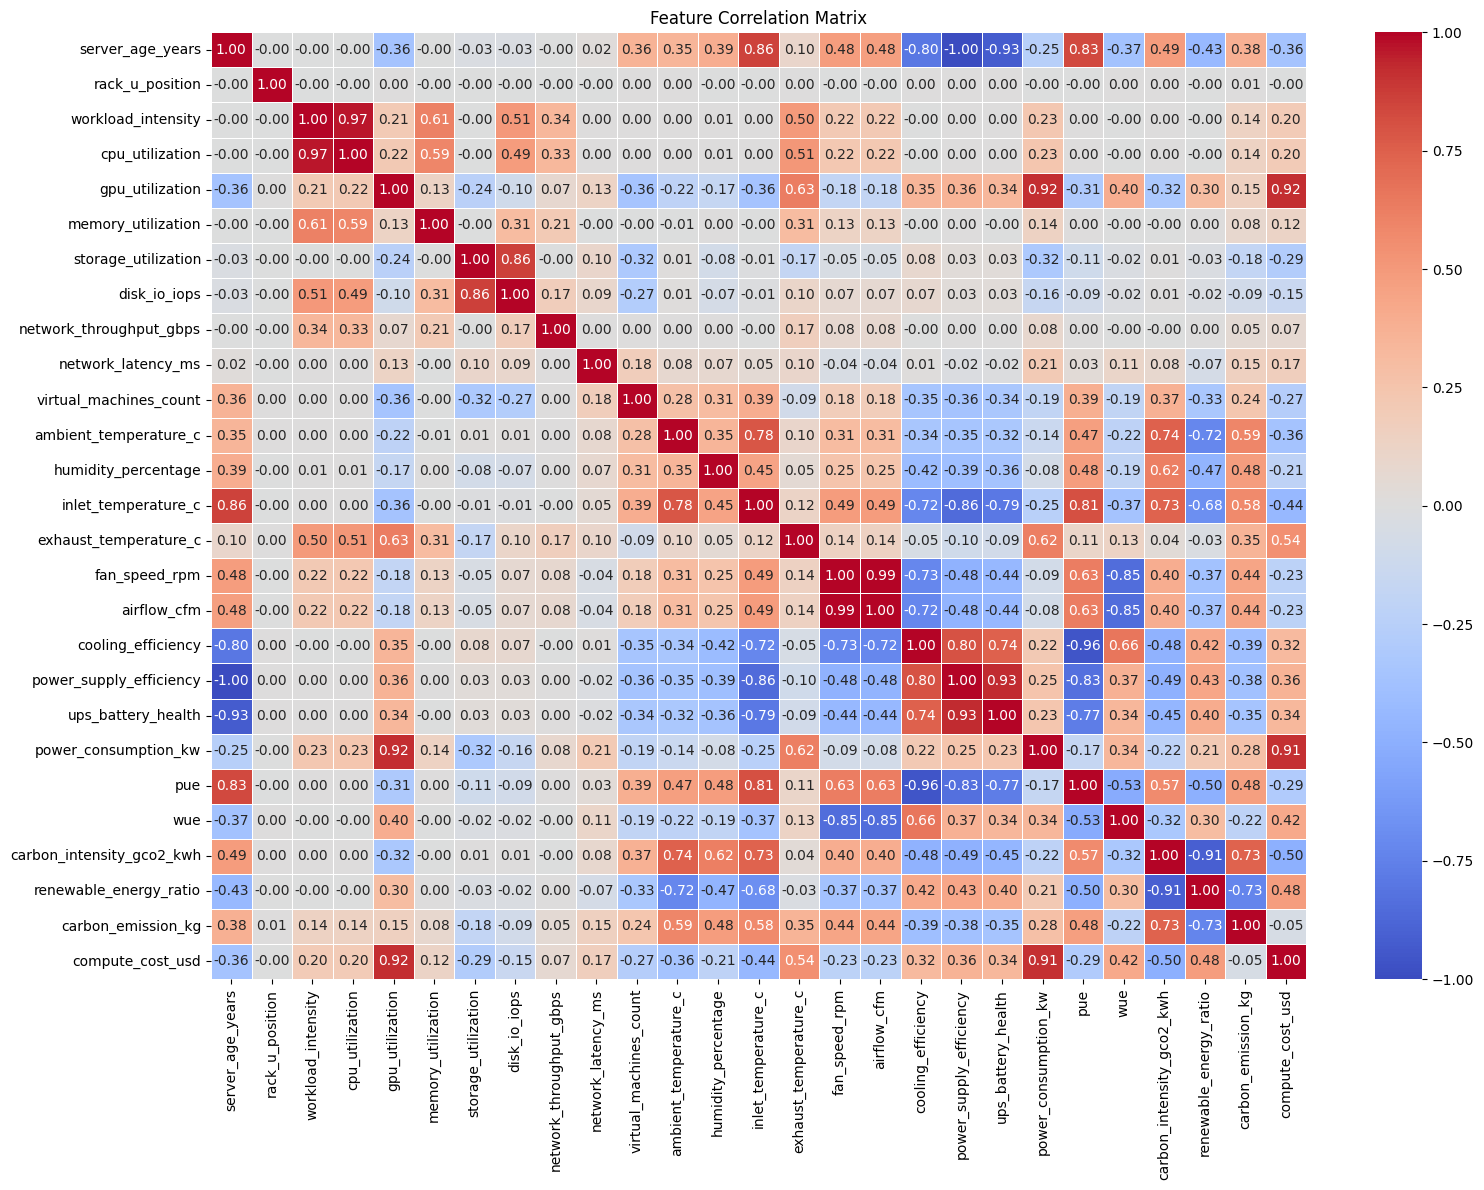

In [17]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

/tmp/ipykernel_667/2476762573.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='failure_risk_level', data=df, palette='coolwarm')


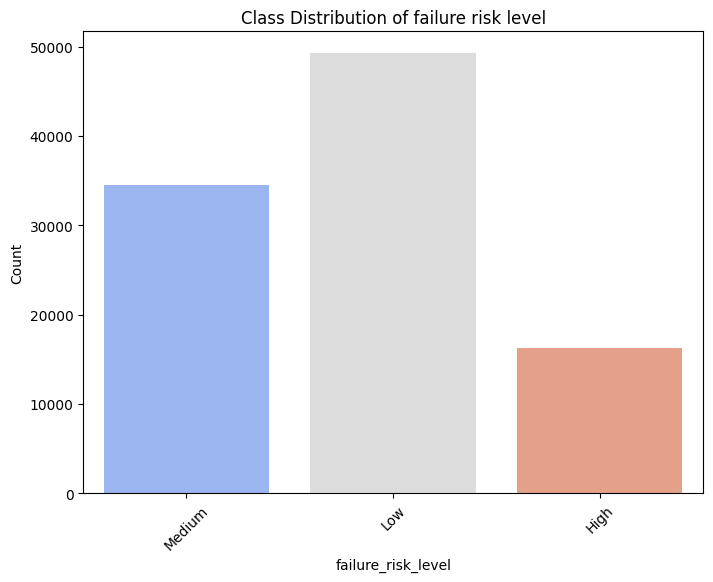

In [18]:
plt.figure(figsize=(8,6))
sns.countplot(x='failure_risk_level', data=df, palette='coolwarm')
plt.title('Class Distribution of failure risk level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Define X and y from the dataset
X = df.drop('failure_risk_level', axis=1)
y = df['failure_risk_level']

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X.select_dtypes(include='number'), y)
importance = pd.Series(rf.feature_importances_,
                       index=X.select_dtypes(include='number').columns).sort_values(ascending=False)
print(importance)

server_age_years             0.237881
power_supply_efficiency      0.212750
ups_battery_health           0.183350
pue                          0.065898
exhaust_temperature_c        0.061021
cooling_efficiency           0.060102
inlet_temperature_c          0.060090
fan_speed_rpm                0.017530
airflow_cfm                  0.015851
carbon_emission_kg           0.010251
power_consumption_kw         0.008866
carbon_intensity_gco2_kwh    0.008249
cpu_utilization              0.007794
gpu_utilization              0.007534
compute_cost_usd             0.007239
workload_intensity           0.006721
renewable_energy_ratio       0.004719
humidity_percentage          0.004150
ambient_temperature_c        0.003581
wue                          0.002925
memory_utilization           0.002421
disk_io_iops                 0.002312
network_throughput_gbps      0.001982
network_latency_ms           0.001898
storage_utilization          0.001865
virtual_machines_count       0.001590
rack_u_posit

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance


# Separate features and target
X = df.drop('failure_risk_level', axis=1).select_dtypes(include='number')
y = df['failure_risk_level']

# Split (important — evaluate on held-out data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train a model first
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Now compute permutation importance on the TEST set
result = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,       # how many times to shuffle each feature
    random_state=42,
    scoring='f1_macro'  # or 'accuracy', 'roc_auc_ovr', etc.
)

# Display results sorted
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean,
    'Std': result.importances_std
}).sort_values('Importance', ascending=False)

print(importance_df)

                      Feature  Importance       Std
0            server_age_years    0.142470  0.001480
19         ups_battery_health    0.131914  0.001529
18    power_supply_efficiency    0.077293  0.000965
14      exhaust_temperature_c    0.067260  0.000573
15              fan_speed_rpm    0.003878  0.000311
3             cpu_utilization    0.002481  0.000372
2          workload_intensity    0.001171  0.000328
16                airflow_cfm    0.001070  0.000230
4             gpu_utilization    0.000932  0.000197
13        inlet_temperature_c    0.000860  0.000252
17         cooling_efficiency    0.000641  0.000258
26           compute_cost_usd    0.000495  0.000176
25         carbon_emission_kg    0.000380  0.000140
11      ambient_temperature_c    0.000267  0.000153
20       power_consumption_kw    0.000260  0.000219
21                        pue    0.000086  0.000225
22                        wue    0.000071  0.000112
5          memory_utilization    0.000023  0.000146
6         st

In [21]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
print("Label mapping:", dict(enumerate(label_encoder.classes_)))

ordinal_encoder = OrdinalEncoder()
cat_cols = X_train.select_dtypes(include="object").columns.to_list()
X_train[cat_cols] = ordinal_encoder.fit_transform(X_train[cat_cols])
X_test[cat_cols] = ordinal_encoder.transform(X_test[cat_cols])


X_tune, X_val, y_tune, y_val = train_test_split(
    X_train, y_train_encoded, test_size=0.3, random_state=42, stratify=y_train_encoded
)
X_search = pd.concat([X_tune, X_val])
y_search = np.concatenate([y_tune, y_val])
split = PredefinedSplit(test_fold=[-1] * len(X_tune) + [0] * len(X_val))

Label mapping: {0: 'High', 1: 'Low', 2: 'Medium'}


In [23]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import numpy as np

# ---------- 1. Select the four features and encode target ----------
features = ['server_age_years', 'ups_battery_health',
            'power_supply_efficiency', 'exhaust_temperature_c']
X = df[features]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df['failure_risk_level'])

# ---------- 2. Train/test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# ---------- 3. XGBoost with class imbalance handling ----------
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weights = weights[y_train]

model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    early_stopping_rounds=20,
    use_label_encoder=False,
    random_state=42,
    verbosity=0
)

model.fit(
    X_train, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

# ---------- 4. Evaluate ----------
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))
print(f"\nMacro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

        High       0.98      1.00      0.99      3254
         Low       1.00      1.00      1.00      9850
      Medium       0.99      0.99      0.99      6896

    accuracy                           0.99     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       0.99      0.99      0.99     20000


Macro F1: 0.9912


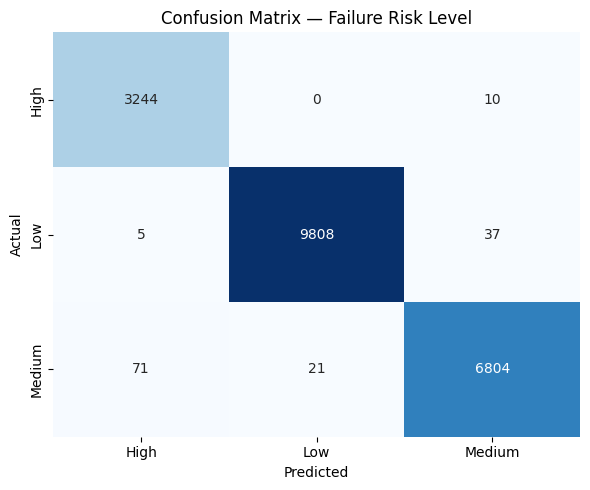

In [24]:
cm = confusion_matrix(y_test, y_pred)

# Plot it
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,               # show the count in each cell
    fmt='d',                  # integer formatting
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar=False
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Failure Risk Level')
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.ensemble import GradientBoostingClassifier

# ---------- 1. Select the four features ----------
features = ['server_age_years', 'ups_battery_health',
            'power_supply_efficiency', 'exhaust_temperature_c']
X = df[features]

# ---------- 2. Train/test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# ---------- 3. XGBoost with class imbalance handling ----------
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weights = weights[y_train]

model = GradientBoostingClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

model.fit(
    X_train, y_train,
    sample_weight=sample_weights
)

# ---------- 4. Evaluate ----------
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))
print(f"\nMacro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

        High       0.98      1.00      0.99      3254
         Low       1.00      1.00      1.00      9850
      Medium       1.00      0.99      0.99      6896

    accuracy                           0.99     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       0.99      0.99      0.99     20000


Macro F1: 0.9934


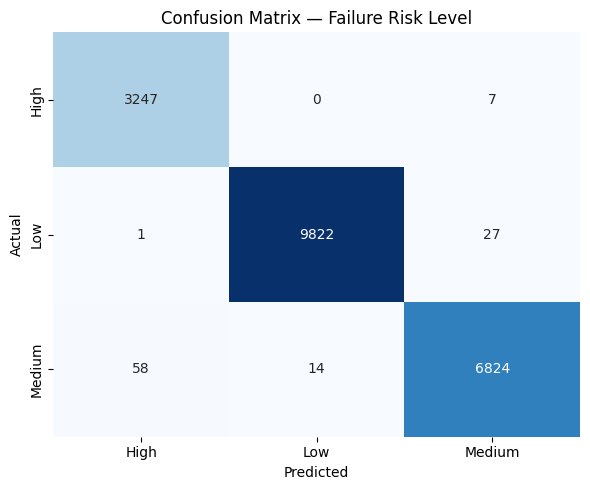

In [45]:
cm = confusion_matrix(y_test, y_pred)

# Plot it
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,               # show the count in each cell
    fmt='d',                  # integer formatting
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar=False
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Failure Risk Level')
plt.tight_layout()
plt.show()